In [4]:
t=0:0.1:10
t_vector= t'
r, = size(t)

#Static data
using Random
V= 14 .+ 3*rand(r)

#Dynamic data
f(x)= 4*sin.(x) +3*cos.(x) .+ 10
h=f(t).+3*rand(r)

size(t)
#using Plots

#p1= plot(t,V,lw=2,label="Static",xlims=(0,10),ylims=(10,17))
#p2= plot(t,h,lw=2,label="Dynamic",xlims=(0,10),ylims=(2,17))

#plot(p1,p2,layout=2,xlabel="time",ylabel="mag")



(101,)

In [ ]:
#Average filter

function mean(x,xs,k)
    return (xs*(k-1))/k + x/k
end

mean_estimate_static=[V[1]]
mean_estimate_dynamic=[h[1]]
# For Static Data

for i in 2:r
    temp= mean(V[i],mean_estimate_static[i-1],i)
    push!(mean_estimate_static,temp)
end

for i in 2:r
    temp= mean(h[i],mean_estimate_dynamic[i-1],i)
    push!(mean_estimate_dynamic,temp)
end


using Plots

p1= plot(t,V,lw=2,label="Static",xlims=(0,10),ylims=(10,17))
    plot!(t,mean_estimate_static,label="Avg_filter",color=r,lw=3)
p2=plot(t,h,lw=2,label="Dynamic",xlims=(0,10),ylims=(2,17))
    plot!(t,mean_estimate_dynamic,label="Avg_filter",clor=r,lw=3)

plot(p1,p2,layout=2)


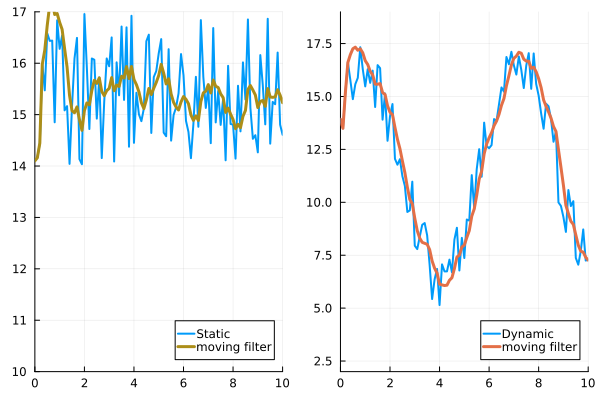

In [5]:
# Moving Filter

function moving_fiter(x,xs,xkn,n)
    return xs+(x/n)-(xkn/n)
end

#initialisation
n=5
estimate_static=[V[1]]
estimate_dynamic=[h[1]]
for k in 2:n-1
    push!(estimate_static,V[k])
end
for k in 2:n-1
    push!(estimate_dynamic,h[k])
end
#Static
for i in n:r
    temp= moving_fiter(V[i],estimate_static[i-1],estimate_static[i-n+1],n)
    push!(estimate_static,temp)
end

#Dynamic
for i in n:r
    temp= moving_fiter(h[i],estimate_dynamic[i-1],estimate_dynamic[i-n+1],n)
    push!(estimate_dynamic,temp)
end

using Plots

p3= plot(t,V,lw=2,label="Static",xlims=(0,10),ylims=(10,17))
    plot!(t,estimate_static,label="moving filter",color=r,lw=3)
p4=plot(t,h,lw=2,label="Dynamic",xlims=(0,10),ylims=(2,19))
    plot!(t,estimate_dynamic,label="moving filter",clor=r,lw=3)

plot(p3,p4,layout=2)

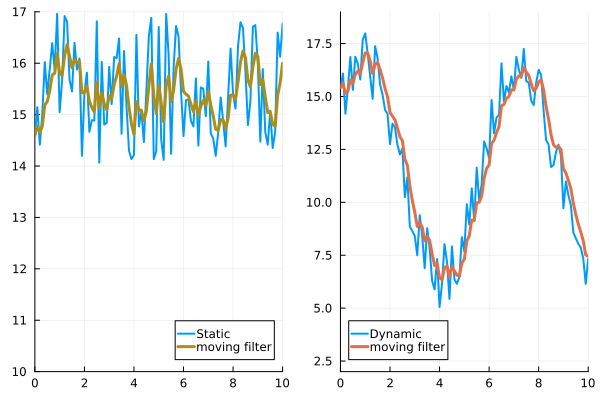

In [31]:
# Low-Pass filter

function low_pass_filter(xs,x,alpha)
    return (xs*alpha + (x*(1-alpha)))
end

#initialisation
alpha=0.67
estimate_static_lpf = []
estimate_dynamic_lpf = []

#Main

for i in 1:r
    if i == 1
        estimate_static_lpf=[V[i]]
        estimate_dynamic_lpf=[h[i]]
    else
        temp1= low_pass_filter(estimate_static_lpf[i-1],V[i],alpha)
        temp2= low_pass_filter(estimate_dynamic_lpf[i-1],h[i],alpha)
        push!(estimate_static_lpf,temp1)
        push!(estimate_dynamic_lpf,temp2)
    end
end

p5= plot(t,V,lw=2,label="Static",xlims=(0,10),ylims=(10,17))
    plot!(t,estimate_static_lpf,label="moving filter",color=r,lw=3)
p6=plot(t,h,lw=2,label="Dynamic",xlims=(0,10),ylims=(2,19))
    plot!(t,estimate_dynamic_lpf,label="moving filter",clor=r,lw=3)

plot(p5,p6,layout=2)


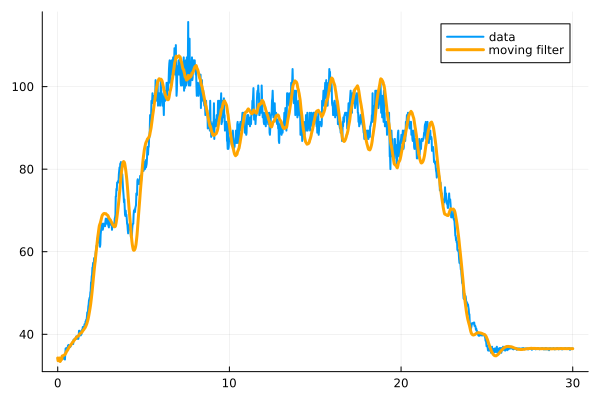

In [6]:
using MAT
vars = matread("/home/plusultra/sim/Kalman_filter_tutorial/SonarAlt.mat")

#println(keys(vars))
sonarAlt= vars["sonarAlt"]'
r, =size(sonarAlt)

Nsamples = 1500
dt = 0.02
t1  = 0:dt:Nsamples*dt

#initialisation
n=15
estimate_sonar=[]
for k in 1:n-1
    push!(estimate_sonar,sonarAlt[k])
end

#Main

for i in n:r
    temp= moving_fiter(sonarAlt[i],estimate_sonar[i-1],estimate_sonar[i-n+1],n)
    push!(estimate_sonar,temp)
end

p7= plot(t1,sonarAlt,lw=2,label="data")
    plot!(t1,estimate_sonar,label="moving filter",color=:orange,lw=3)


In [7]:
# Kalman-Filter

### xps= A*xs   ps= A*p*At   k= ps*ht*(h*ps*ht)^-1   xs=xps+k*(z-h*xps)    p=ps-k*h*ps
using LinearAlgebra

function kalman_filter(A,xs,p,h,z,r,q)
    xps= A*xs
    ps= A*p*A'+q
    k= ps*(h')*inv((h*ps*h' + r))
    xs= xps + k*(z-h*xps)
    p=ps-k*h*ps
    
    return xs,p

end

#initialisation
A=1
H=1
R=4
xs=14;
p=6;
estimate_kalman=[]
error=[]

for i in 1:r
    xs, p=kalman_filter(A,xs,p,H,V[i],R,0)
    push!(estimate_kalman,xs)
    push!(error,p)
end

using Plots

p8= plot(t,V,lw=2,label="Static",xlims=(0,10),ylims=(10,17))
    plot!(t,estimate_kalman,label="kalman filter",color=r,lw=3)

p9=plot(t,error,label="kalman filter",color=:red,lw=3)

plot(p8,p9,layout=2)


LoadError: BoundsError: attempt to access 101-element Vector{Float64} at index [102]

In [ ]:
#initialisation
using LinearAlgebra

r, =size(sonarAlt)

I2 = Matrix{Float64}(I, 2, 2)
Nsamples = 1500
dt = 0.02
t1  = 0:dt:Nsamples*dt

A=[1 dt; 0 1]
H=[1 0]
Q=[1 0; 0 3]
R=10

x = [0 20]'
P = 5*I2

estimate_sonar_kalman_x=[]
estimate_sonar_kalman_v=[]
error_sonar_x=[]
error_sonar_v=[]
v_fintie_difference=[]

for i in 1:r
    x, P = kalman_filter(A,x,P,H,[sonarAlt[i]],[R],Q)
    push!(estimate_sonar_kalman_x,x[1,1])
    push!(estimate_sonar_kalman_v,x[2,1])
    push!(error_sonar_x,P[1,1])
    push!(error_sonar_v,P[2,2])
    if i == 1 || i == r
        push!(v_fintie_difference,(sonarAlt[i]/dt))
    else
        push!(v_fintie_difference,((sonarAlt[i]-sonarAlt[i-1])/dt))
    end
end


using Plots
plotly()

p10= plot(t1,sonarAlt,lw=2,label="data")
    plot!(t1,estimate_sonar_kalman_x,label="kalman filter",color=:orange,lw=3)

p11= plot(t1,error_sonar_x,label="error x",color=:red,lw=3)

p12= plot(t1,estimate_sonar_kalman_v,label="kalman filter velocity",color=:purple,lw=3)
    plot!(t1,v_fintie_difference,label="v through finite difference",lw=1)
p13= plot(t1,error_sonar_v,label="error v",color=:red,lw=3)

plot(p10,p11,p12,p13,layout=4)


